# Tutorial 2 — Designing an OWChirp waveform

Use `OWChirpGeneration` to design an Optimally Windowed Chirp (OWCh)
signal and export it as text file to use to design a TA TRIOS *Arbitrary Wave* . An OWCh is a
constant-amplitude sinusoid whose instantaneous frequency is swept
**exponentially** from $\omega_0$ to $\omega_1$ over a duration $T$,

$$
\omega(t) = \omega_0 \left(\frac{\omega_1}{\omega_0}\right)^{t/T},
$$

and then multiplied by a cosine-tapered (Tukey) window that suppresses
spectral leakage and nonlinear artefacts at the signal edges. The
generator computes:

- The piecewise Tukey (raised-cosine) tapering, set by the fraction $r$
  (Geri et al. find $0.05 \le r \le 0.15$ works well; $r = 0$ disables
  tapering).
- The exponential frequency sweep from $\omega_0$ to $\omega_1$.
- The time–bandwidth product $TB = T(\omega_1 - \omega_0)/2\pi$, which
  should satisfy $TB \gtrsim 100$ to keep spectral leakage low.

It produces a `.txt` waveform, a `.png` plot and a `.txt` parameter file
you can paste straight into the TRIOS *Arbitrary Wave* dialog.

:::{seealso}
- Geri, M., Keshavarz, B., Divoux, T., Clasen, C., Curtis, D. J. and
  McKinley, G. H. (2018), *Time-Resolved Mechanical Spectroscopy of
  Soft Materials via Optimally Windowed Chirps*, Phys. Rev. X **8**,
  041042. DOI: [`10.1103/PhysRevX.8.041042`](https://doi.org/10.1103/PhysRevX.8.041042).
- Perego, A. *et al.* (2025), *Evaluation of Optimally Windowed Chirp
  Signals in Industrial Rheological Measurements: Method Development and
  Data Processing*, Rheologica Acta.
  DOI: [`10.1007/s00397-025-01511-0`](https://link.springer.com/article/10.1007/s00397-025-01511-0).
- Ghiringhelli, E., Roux, D., Bleses, D., Galliard, H. and Caton, F.
  (2012), *Optimal Fourier rheometry*, Rheologica Acta **51**(5),
  413–420. DOI: [`10.1007/s00397-012-0616-z`](https://doi.org/10.1007/s00397-012-0616-z).
:::


## 1 — Set the chirp parameters

`OWChirpGeneration` is a plain helper class (not a `MeasurementTransform`).
You configure it once with the parameters you want, then use the
resulting object to introspect, save, and visualise the signal.

- `waiting_time` — pre-signal quiet interval (s). The data acquired
  during this window are used to quantify and remove systematic offsets
  (e.g. motor bias, encoder drift) before the FFT, reducing spectral
  leakage.
- `signal_duration` — total chirp duration $T$ (s).
- `strain_amplitude` — dimensionless (0.01 = 1%).
- `initial_frequency`, `final_frequency` — $\omega_0$, $\omega_1$ in **rad/s**.
- `tapering_parameter` — Tukey (raised-cosine) window fraction $r$
  ($r = 0$ disables tapering; $0.05 \le r \le 0.15$ is recommended).
- `initial_phase_shift` — starting phase in degrees.


In [1]:
from hermes_rheo.transforms.owchirp_generation import OWChirpGeneration
from hermes_rheo.visualization import use_science_style # Publication-quality Matplotlib styling

use_science_style()

owchirp_signal = OWChirpGeneration(
    output_file_name='chirp_signal_parameters.txt',
    waiting_time=1,
    signal_duration=14,
    strain_amplitude=8.5e-5,
    initial_frequency=0.3,
    final_frequency=60,
    tapering_parameter=0.1,
    initial_phase_shift=0
)

## 2 — Inspect the derived parameters

Once constructed, the object exposes derived quantities you'll need to design the Arbitrary Wave in TA TRIOS: total time-bandwidth product $TB$, the piecewise zone
equations, and the shortest chirp duration compatible with the chosen
$\omega_0$.

In [2]:
owchirp_signal.print_parameters()

Shorter chirp signal: 13.9626 (s), TB = 133.0
Total length of chirp signal: 14 (s)
Initial Frequency: 0.3 (rad/s)
Final Frequency: 60 (rad/s)
Strain amplitude: 8.5e-05 
Waiting time: 1 (s)
Tapering parameter: 0.1 
Time Bandwidth: 133.0
Initial Phase Shift: 0 (°)
-------------------------------------------------------------------------
For t = waiting_time = 1s write: 0
For the first segment duration = 0.7s write: 8.5e-05*cos(2.244*t -3.8148)^2*sin(0.5428*exp(0.3785*t)-0.7926+0.0)
For the second segment duration = 12.6s write: 8.5e-05*sin(0.5428*exp(0.3785*t)-0.7926+0.0)
For the third segment duration = 0.7s write: 8.5e-05*cos(2.244*t -32.0891)^2*sin(0.5428*exp(0.3785*t)-0.7926+0.0)
--------------------------------------------------------------------------


## 3 — Choose an output folder

Everything downstream (`.txt` parameters, waveform `.txt`, `.png`
snapshot) will be written under `tutorial_data/tutorial_2/`.

In [3]:
import os

# Get the current directory where the notebook is located
current_dir = os.path.dirname(os.path.abspath("__file__"))  # Use "__file__" to get the notebook's directory

# Specify where to save the file and name of the file
filepath = os.path.join(current_dir, 'tutorial_data', 'tutorial_2')

## 4 — Save the parameter file

`to_txt` writes a human-readable summary of every parameter plus the
piecewise zone equations you need to enter in the TRIOS.

In [4]:
owchirp_signal.to_txt(filepath) 

## 5 — Plot the waveform

`visualize` renders the tapered chirp side-by-side with the un-tapered
($r = 0$) reference, saves both `.txt` samples and a `.png` snapshot to
the output folder.  The vertical dashed line marks the end of the
waiting window.

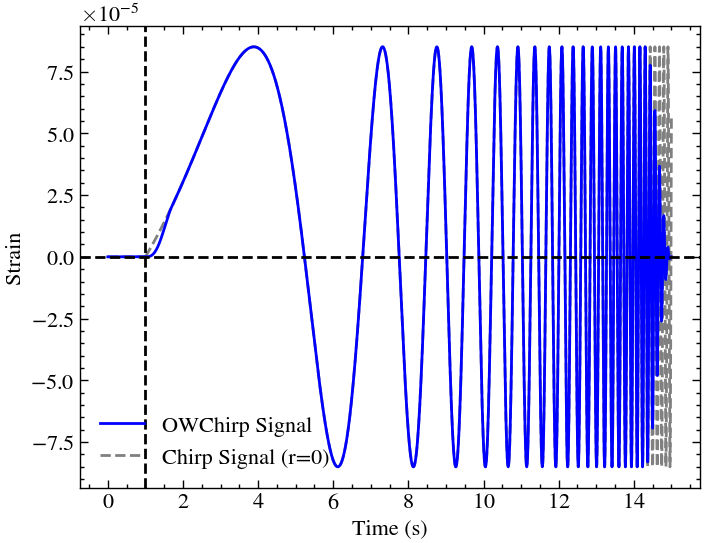

In [5]:
owchirp_signal.visualize(display_r0=True, filepath=filepath)  #save figure and data to filepath location